# NB02 - Simulasi Buta Warna Parsial

Input utama adalah `NB01/output/confusion_line_selected_by_cvd.csv`. Setiap baris menyatakan satu citra yang dipilih untuk satu tipe CVD setelah filter dan undersampling NB01. Baris protan hanya menghasilkan simulasi protan dan baris deutan hanya menghasilkan simulasi deutan, masing-masing pada severity 0.25, 0.50, 0.75, dan 1.00. Citra yang terpilih untuk keduanya menghasilkan delapan keluaran.

Citra masukan dibaca dari `NB01/output/confusion_line_filtered/<cvd>/<fruit>_<id>.png` dan diperiksa SHA-256-nya terhadap manifest. Keluaran berada di `simulated_images/<cvd>/<severity>/<fruit>_<id>.png`. Kelas buah tetap disimpan sebagai metadata audit. Keanggotaan ditentukan manifest, sehingga berkas sisa eksekusi sebelumnya tidak ikut diproses.

Kelompok seleksi protan dan deutan dapat berisi citra berbeda. Ringkasan antar kelompok bersifat deskriptif; NB03 juga menyediakan perbandingan berpasangan untuk irisan citra.


In [1]:
%pip install opencv-python-headless numpy pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Konfigurasi

In [ ]:
from __future__ import annotations
import sys, time, re
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((p for p in CORE_CANDIDATES if (p / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/ tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from machado import simulate_machado_bgr
from utils import find_research_root, sha256_file, write_csv, write_json
RESEARCH_ROOT=find_research_root("notebooks/01/output/confusion_line_selected_by_cvd.csv")
MANIFEST_PATH=RESEARCH_ROOT/"notebooks/01/output/confusion_line_selected_by_cvd.csv"
OUTPUT_DIR=RESEARCH_ROOT/"notebooks/02/output"
SIMULATED_DIR=OUTPUT_DIR/"simulated_images"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True); SIMULATED_DIR.mkdir(parents=True,exist_ok=True)
CVD_FAMILIES=("protan","deutan")
SEVERITIES=(0.25,0.50,0.75,1.00)
NB01_IMAGE_DIR = MANIFEST_PATH.parent / "confusion_line_filtered"


## Tahap 2 - Memuat dan Memeriksa Manifest Praproses

In [3]:
manifest = pd.read_csv(MANIFEST_PATH)
SOURCE_KEY = ["subset", "source_class", "source_file_name"]
SELECTION_KEY = [*SOURCE_KEY, "cvd_family"]
required = {*SELECTION_KEY, "output_sha256", "ambiguity_threshold", "protan_pair_distance_median", "deutan_pair_distance_median"}
missing = required - set(manifest.columns)
if missing:
    raise ValueError(f"Jalankan NB01 terbaru. Kolom manifest belum lengkap: {sorted(missing)}")
if manifest.empty or manifest[list(required)].isna().any().any():
    raise ValueError("Manifest seleksi NB01 kosong atau berisi nilai wajib yang kosong.")
if manifest.duplicated(SELECTION_KEY).any():
    raise ValueError("Manifest memiliki pasangan citra dan tipe CVD yang berulang.")
if not manifest["cvd_family"].isin(CVD_FAMILIES).all():
    raise ValueError("Tipe CVD pada manifest tidak dikenal.")
manifest = manifest.sort_values(SELECTION_KEY).reset_index(drop=True)
manifest["selection_group"] = manifest["cvd_family"].map(lambda family: f"confusion_line_{family}")
manifest["selected_file_name"] = manifest.apply(
    lambda row: re.sub(r"^\d+", "", row["source_class"]) + "_" + Path(row["source_file_name"]).stem + ".png",
    axis=1,
)
manifest["selected_input_path"] = manifest.apply(
    lambda row: str(NB01_IMAGE_DIR / row["cvd_family"] / row["selected_file_name"]), axis=1,
)
if manifest.duplicated(["cvd_family", "selected_file_name"]).any():
    raise ValueError("Nama berkas datar NB01 bertabrakan antar citra. Perbaiki ekspor NB01.")
for row in manifest.itertuples(index=False):
    path = Path(row.selected_input_path)
    if not path.is_file() or sha256_file(path) != row.output_sha256:
        raise ValueError(f"Berkas seleksi NB01 hilang atau hash berbeda: {path}. Jalankan ulang NB01.")
print(f"Citra unik: {len(manifest[SOURCE_KEY].drop_duplicates())}")
print("Jumlah citra terpilih per tipe CVD:")
print(manifest.groupby("cvd_family").size().to_string())
print(manifest.groupby(["cvd_family", "source_class"]).size().to_string())


Citra unik: 949
Jumlah citra terpilih per tipe CVD:
cvd_family
deutan    525
protan    525
cvd_family  source_class  
deutan      001apple          35
            002orange         35
            003pear           35
            006banana         35
            007watermelon     35
            008kiwi           35
            009peach          35
            011pineapple      35
            012starfruit      35
            014lemon          35
            015pomelo         35
            016mango          35
            017durian         35
            018hami           35
            019papaya         35
protan      001apple          29
            002orange         35
            003pear           28
            004tomato         34
            005strawberry     37
            007watermelon     34
            008kiwi           29
            009peach          30
            010pomegranate    37
            011pineapple      35
            012starfruit      27
            013grape    

## Tahap 3 - Menyusun Empat Severity per Pasangan Citra dan Tipe CVD


In [4]:
def severity_folder(severity: float) -> str:
    return f"severity_{int(round(severity * 100)):03d}"


def simulation_output_path(row: pd.Series, cvd_family: str, severity: float) -> Path:
    return SIMULATED_DIR / cvd_family / severity_folder(severity) / row["selected_file_name"]


jobs = []
for _, row in manifest.iterrows():
    cvd_family = row["cvd_family"]
    for severity in SEVERITIES:
        jobs.append({
            **{key: row[key] for key in SOURCE_KEY},
            "selection_group": row["selection_group"],
            "selection_distance_median": float(row[f"{cvd_family}_pair_distance_median"]),
            "ambiguity_threshold": float(row["ambiguity_threshold"]),
            "input_path": row["selected_input_path"],
            "input_sha256": row["output_sha256"],
            "cvd_family": cvd_family,
            "severity": severity,
            "output_path": str(simulation_output_path(row, cvd_family, severity)),
        })
if pd.DataFrame(jobs)["output_path"].duplicated().any():
    raise ValueError("Ada pekerjaan simulasi yang menulis ke berkas yang sama.")
print(f"Jumlah pekerjaan: {len(manifest)} pasangan seleksi x {len(SEVERITIES)} severity = {len(jobs)}")


Jumlah pekerjaan: 1050 pasangan seleksi x 4 severity = 4200


## Tahap 4 - Menjalankan Simulasi Machado

In [5]:
report_rows = []
error_rows = []
started = time.perf_counter()

for index, job in enumerate(jobs, start=1):
    try:
        source = cv2.imread(job["input_path"], cv2.IMREAD_COLOR)
        if source is None:
            raise ValueError("Citra masukan tidak dapat dibaca")
            
        target = Path(job["output_path"])
        target.parent.mkdir(parents=True, exist_ok=True)
        
        # Eksekusi fungsi simulasi
        result, diagnostics = simulate_machado_bgr(
            source, job["cvd_family"], float(job["severity"])
        )
        
        if not cv2.imwrite(str(target), result):
            raise IOError("Citra hasil tidak dapat ditulis")
            
        # Hitung metrik yang belum disediakan oleh engine secara langsung
        difference = np.abs(result.astype(np.int16) - source.astype(np.int16))
        mean_abs_rgb_diff = float(difference.mean() / 255.0)
        changed_pixel_prop = float(np.any(result != source, axis=2).mean())
        
        # Petakan key dari engine (clip_*_ratio -> clipping_*_proportion)
        report_rows.append({
            **job,
            "output_sha256": sha256_file(target),
            "mean_absolute_rgb_difference": mean_abs_rgb_diff,
            "changed_pixel_proportion": changed_pixel_prop,
            "clipping_low_proportion": diagnostics["clip_low_ratio"],
            "clipping_high_proportion": diagnostics["clip_high_ratio"],
            "clipping_any_proportion": diagnostics["clip_any_ratio"],
        })
        
    except Exception as error:
        error_rows.append({**job, "error": str(error)})
        
    if index % 1000 == 0 or index == len(jobs):
        print(f"{index}/{len(jobs)} pekerjaan selesai, {time.perf_counter()-started:.1f} detik")

# Simpan kegagalan sebelum menghentikan pipeline agar hasil parsial tidak dianggap lengkap.
if error_rows:
    pd.DataFrame(error_rows).to_csv(OUTPUT_DIR / "simulation_errors.csv", index=False)
    raise RuntimeError(f"Ada {len(error_rows)} simulasi gagal. Periksa simulation_errors.csv lalu jalankan ulang NB02.")

# Handling aman jika seluruh proses gagal
if not report_rows:
    error_frame = pd.DataFrame(error_rows)
    print("\n[ERROR] Sampel kesalahan yang terjadi selama simulasi:")
    print(error_frame[["cvd_family", "severity", "error"]].head().to_string(index=False))
    raise RuntimeError("Semua simulasi gagal. Periksa log error di atas.")

# Pengurutan dilakukan setelah memastikan report_rows tidak kosong
report = (
    pd.DataFrame(report_rows)
    .sort_values(["cvd_family", "severity", "source_class", "source_file_name"])
    .reset_index(drop=True)
)

print(f"Simulasi berhasil: {len(report)} | gagal: {len(error_rows)}")


1000/4200 pekerjaan selesai, 130.9 detik
2000/4200 pekerjaan selesai, 259.3 detik
3000/4200 pekerjaan selesai, 407.5 detik
4000/4200 pekerjaan selesai, 533.1 detik
4200/4200 pekerjaan selesai, 568.5 detik
Simulasi berhasil: 4200 | gagal: 0


## Tahap 5 - Verifikasi Struktur Keluaran

In [6]:
verification=[]
for _, row in report.iterrows():
    image=cv2.imread(row["output_path"],cv2.IMREAD_COLOR)
    verification.append({"output_path":row["output_path"],"readable":image is not None,"width":None if image is None else int(image.shape[1]),"height":None if image is None else int(image.shape[0])})
verification=pd.DataFrame(verification)
if not verification["readable"].all(): raise RuntimeError("Ada citra simulasi yang tidak dapat dibaca.")
print(f"Seluruh {len(verification)} keluaran simulasi dapat dibaca.")

Seluruh 4200 keluaran simulasi dapat dibaca.


## Tahap 6 - Visualisasi Perubahan Severity

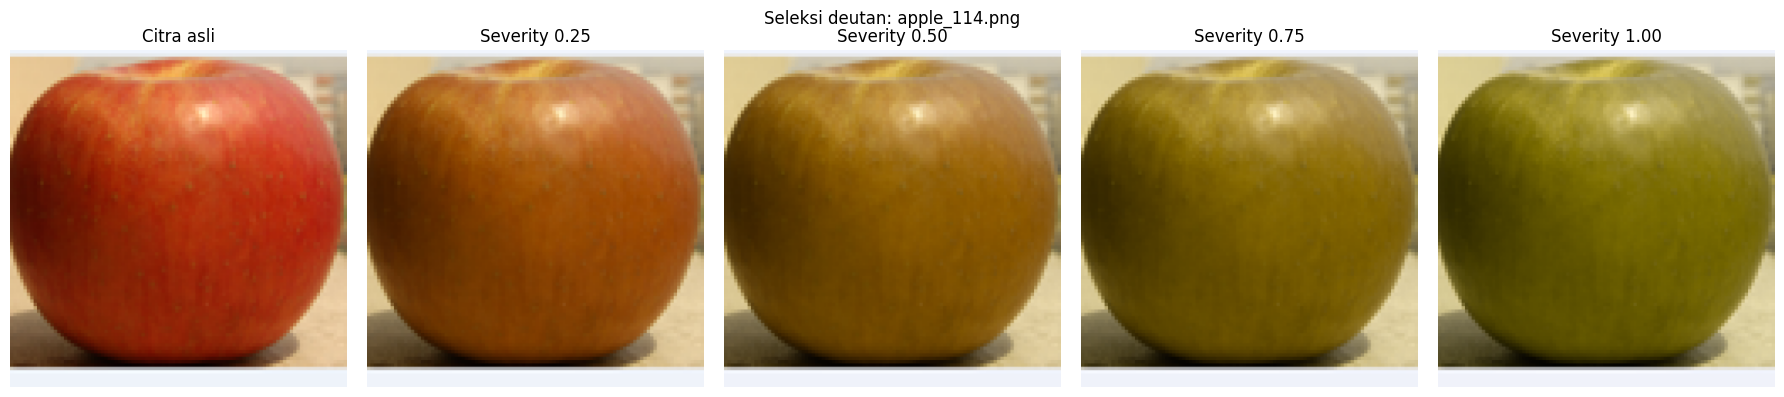

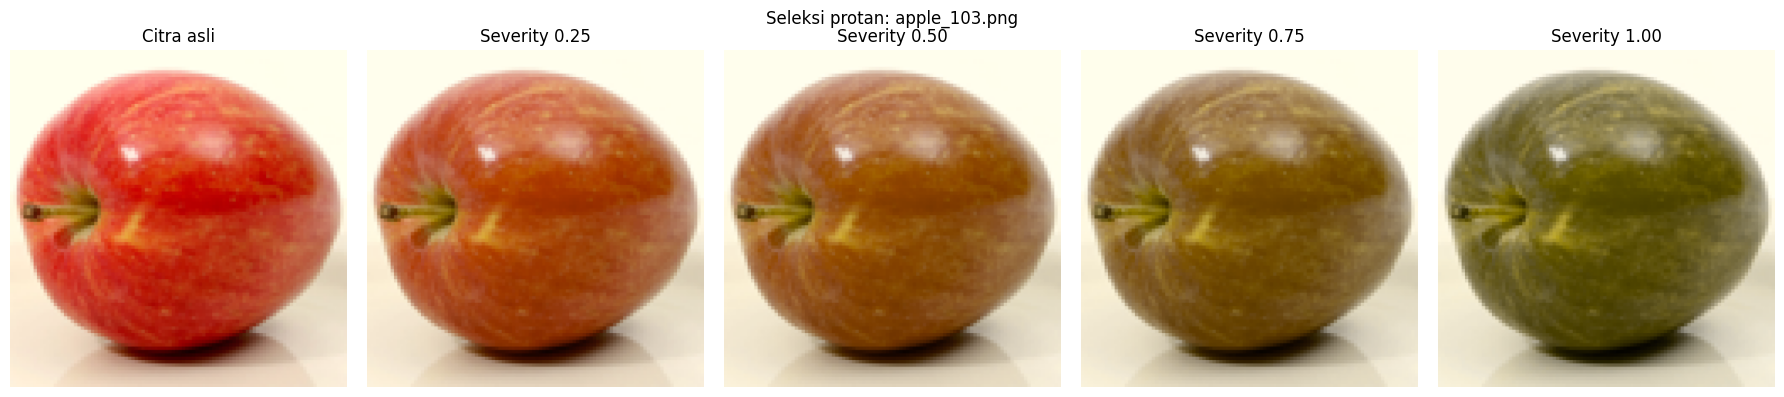

In [7]:
for cvd_family, candidates in manifest.groupby("cvd_family", sort=True):
    representative = candidates.iloc[0]
    fig, axes = plt.subplots(1, len(SEVERITIES) + 1, figsize=(18, 4))
    original = cv2.imread(representative["selected_input_path"], cv2.IMREAD_COLOR)
    if original is None:
        raise ValueError("Citra contoh NB01 tidak dapat dibaca.")
    axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Citra asli")
    axes[0].axis("off")
    for axis, severity in zip(axes[1:], SEVERITIES):
        path = simulation_output_path(representative, cvd_family, severity)
        result = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if result is None:
            raise ValueError(f"Citra contoh simulasi tidak tersedia: {path}")
        axis.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
        axis.set_title(f"Severity {severity:.2f}")
        axis.axis("off")
    fig.suptitle(f"Seleksi {cvd_family}: {representative['selected_file_name']}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"simulation_severity_{cvd_family}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## Tahap 7 - Ekspor Laporan dan Ringkasan Simulasi per Kelompok Seleksi dan Kelas


In [8]:
# 1. Simpan laporan simulasi utama
write_csv(report, OUTPUT_DIR / "simulation_report.csv", ["subset", "source_class", "source_file_name", "cvd_family", "severity"])

# Ringkasan simulasi 3 level pembantu Bab 5: Global, Kelompok Seleksi, dan Kelas Buah
group_summary = report.groupby(["cvd_family", "severity"], as_index=False).agg(
    image_count=("output_path", "size"),
    mean_absolute_rgb_difference=("mean_absolute_rgb_difference", "mean"),
    changed_pixel_proportion=("changed_pixel_proportion", "mean"),
    clipping_any_proportion=("clipping_any_proportion", "mean")
)

selection_summary = report.groupby(["cvd_family", "severity", "selection_group"], as_index=False).agg(
    image_count=("output_path", "size"),
    mean_absolute_rgb_difference=("mean_absolute_rgb_difference", "mean"),
    changed_pixel_proportion=("changed_pixel_proportion", "mean"),
    clipping_any_proportion=("clipping_any_proportion", "mean")
)

class_summary = report.groupby(["cvd_family", "severity", "selection_group", "source_class"], as_index=False).agg(
    image_count=("output_path", "size"),
    mean_absolute_rgb_difference=("mean_absolute_rgb_difference", "mean"),
    changed_pixel_proportion=("changed_pixel_proportion", "mean"),
    clipping_any_proportion=("clipping_any_proportion", "mean")
)

# 2. Simpan laporan error (dengan proteksi jika error_rows kosong)
error_cols = ["subset", "source_class", "source_file_name", "cvd_family", "severity", "error"]
df_errors = pd.DataFrame(error_rows) if error_rows else pd.DataFrame(columns=error_cols)
write_csv(df_errors, OUTPUT_DIR / "simulation_errors.csv", ["source_class", "source_file_name", "cvd_family", "severity"], allow_empty=True)

# 3. Simpan verifikasi dan ringkasan kelompok untuk tabel Bab 5
write_csv(verification, OUTPUT_DIR / "simulation_verification.csv", ["output_path"])
write_csv(group_summary, OUTPUT_DIR / "simulation_group_summary.csv", ["cvd_family", "severity"])
write_csv(selection_summary, OUTPUT_DIR / "simulation_selection_summary.csv", ["cvd_family", "severity", "selection_group"])
write_csv(class_summary, OUTPUT_DIR / "simulation_class_summary.csv", ["cvd_family", "severity", "selection_group", "source_class"])

# 4. Simpan summary JSON
write_json({
    "source_image_count": len(manifest[SOURCE_KEY].drop_duplicates()),
    "selected_image_family_count": len(manifest),
    "source_counts_by_family": {key: int(value) for key, value in manifest.groupby("cvd_family").size().items()},
    "selection_manifest_sha256": sha256_file(MANIFEST_PATH),
    "severity_count_per_selected_family": len(SEVERITIES),
    "expected_simulation_count": len(jobs),
    "successful_simulation_count": len(report),
    "error_count": len(error_rows),
    "cvd_families": list(CVD_FAMILIES),
    "severities": list(SEVERITIES),
    "selection_groups": sorted(report["selection_group"].unique().tolist())
}, OUTPUT_DIR / "simulation_summary.json")

group_summary


,cvd_family,severity,image_count,mean_absolute_rgb_difference,changed_pixel_proportion,clipping_any_proportion
0,deutan,0.25,525,0.015432,0.874745,0.127505
1,deutan,0.50,525,0.025141,0.906701,0.133543
2,deutan,0.75,525,0.031864,0.917615,0.096968
3,deutan,1.00,525,0.037151,0.924346,0.131391
4,protan,0.25,525,0.022345,0.914194,0.172392
5,protan,0.50,525,0.037376,0.932773,0.199795
6,protan,0.75,525,0.048977,0.936425,0.182219
7,protan,1.00,525,0.059140,0.937189,0.232321
